# 泰勒展开与牛顿法coding

### 作业一：牛顿法比梯度下降快在哪里？
牛顿法是泰勒二阶，梯度下降是泰勒一阶




### 作业二：Hessian 代价大，代价指的是什么？

1. 存储代价
2. 求逆代价
3. 不一定正定，可能发散，需要加阻尼（保证矩阵可逆，性质最大步长）
4. 奇异Hessian：det(H)=0 存在0特征值，矩阵不可逆，H-1不存在;病态Hessian：$\frac{最大特征值}{最小特征值}$极大，代表不同方向的曲率差几个数量级，求逆报错

信息的价值往往永远伴随计算的代价

牛顿法 斜率曲率(二阶)，快但贵到离谱(Hessian)梯度下降斜率(一阶)，便宜但走的慢!没有最好的算法，只有最合适当前资源限制的算法
BFGS、L-BFGS近似
DL Adam 一阶方法 原因不是理论收敛最快，而是算力、内存、效果，找到best balance


确定性有时候会困住你，噪音会救命
鞍点
SGD（随机采样）噪声  反而梯度下降“歪打正着”
如果太去追求局部最优，往往困在原地，保持一定随机性反而能取得更好的效果

做任何的决策或近似，都要有量化风险的意识，而不是稀里糊涂地“差不多就行”



In [2]:
import numpy as  np
import matplotlib.pyplot as plt
from math import factorial

plt.rcParams['font.sans-serif']=['SimHei']
plt.rcParams['axes.unicode_minus'] = False

print('Success!!!')

Success!!!


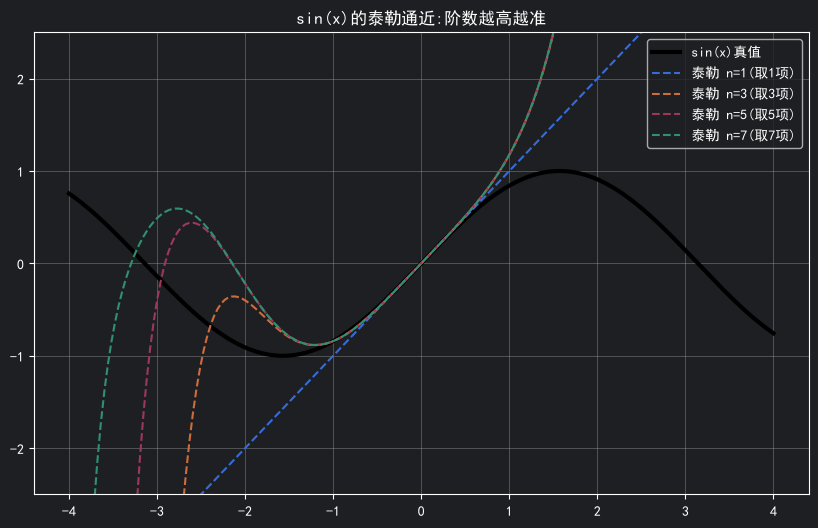

In [3]:
#泰勒展开：用多项式逼近
def taylor_sin(x,n):
    s = 0.0
    for k in range(n):
        s += x**k*x**(2*k+1)/factorial(2*k+1)
    return s

x = np.linspace(-4,4,200)

plt.figure(figsize=(10,6))
plt.plot(x,np.sin(x),'k-',linewidth=3,label='sin(x)真值')

for n in [1,3,5,7]:
    plt.plot(x,taylor_sin(x,n),'--',label=f'泰勒 n={n}(取{n}项)')
plt.ylim(-2.5, 2.5)
plt.legend()
plt.grid(True)
plt.title('sin(x)的泰勒通近:阶数越高越准')
plt.show()


In [4]:
x_test = 2.0
true_val = np.sin(x_test)
print('x = 2, sin(2) =', true_val)

for n in [1, 2, 3, 5, 8, 12]:
    approx = taylor_sin(x_test, n)
    err = abs(approx - true_val)
    print(f"n={n:2d} 项: 近似={approx:.6f}, 误差={err:.2e}")

x = 2, sin(2) = 0.9092974268256817
n= 1 项: 近似=2.000000, 误差=1.09e+00
n= 2 项: 近似=4.666667, 误差=3.76e+00
n= 3 项: 近似=5.733333, 误差=4.82e+00
n= 5 项: 近似=5.959083, 误差=5.05e+00
n= 8 项: 近似=5.960812, 误差=5.05e+00
n=12 项: 近似=5.960812, 误差=5.05e+00


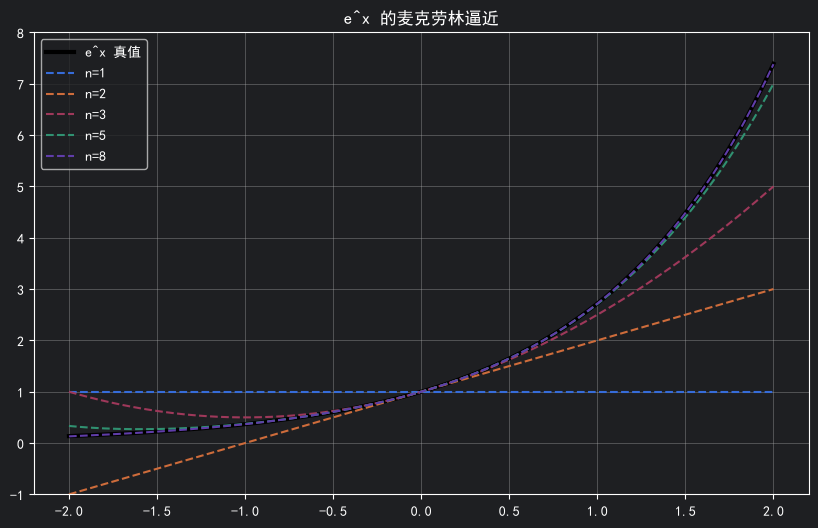

In [5]:
def taylor_exp(x, n):
    return sum(x**k / factorial(k) for k in range(n))

x = np.linspace(-2, 2, 200)
plt.figure(figsize=(10, 6))


plt.plot(x, np.exp(x), 'k-', linewidth=3, label='e^x 真值')

for n in [1, 2, 3, 5, 8]:

    plt.plot(x, taylor_exp(x, n), '--', label=f'n={n}')

plt.ylim(-1, 8)
plt.legend()
plt.grid(True)
plt.title('e^x 的麦克劳林逼近')
plt.show()

In [6]:
for n in [1, 2, 3, 5]:
    print(f'n={n}: e^0.1 ≈ {taylor_exp(0.1, n):.7f}')
print(f'真值 e^0.1 = {np.exp(0.1):.7f}')

n=1: e^0.1 ≈ 1.0000000
n=2: e^0.1 ≈ 1.1000000
n=3: e^0.1 ≈ 1.1050000
n=5: e^0.1 ≈ 1.1051708
真值 e^0.1 = 1.1051709


In [7]:
#牛顿法
def newton_sqrt2(x0=1.5,iters=8):
    x = x0
    hist =[x]
    for i in range(iters):
        x= x-(x**2)/(2*x)
        hist.append(x)
        print(f'第{i+1}步：x={i:.10f}，误差={abs(x-2**0.5):.2e}')
    return x,hist


print('真实 sqrt(2) =', 2**0.5)
print()
final, hist = newton_sqrt2(1.5, 8)

真实 sqrt(2) = 1.4142135623730951

第1步：x=0.0000000000，误差=6.64e-01
第2步：x=1.0000000000，误差=1.04e+00
第3步：x=2.0000000000，误差=1.23e+00
第4步：x=3.0000000000，误差=1.32e+00
第5步：x=4.0000000000，误差=1.37e+00
第6步：x=5.0000000000，误差=1.39e+00
第7步：x=6.0000000000，误差=1.40e+00
第8步：x=7.0000000000，误差=1.41e+00


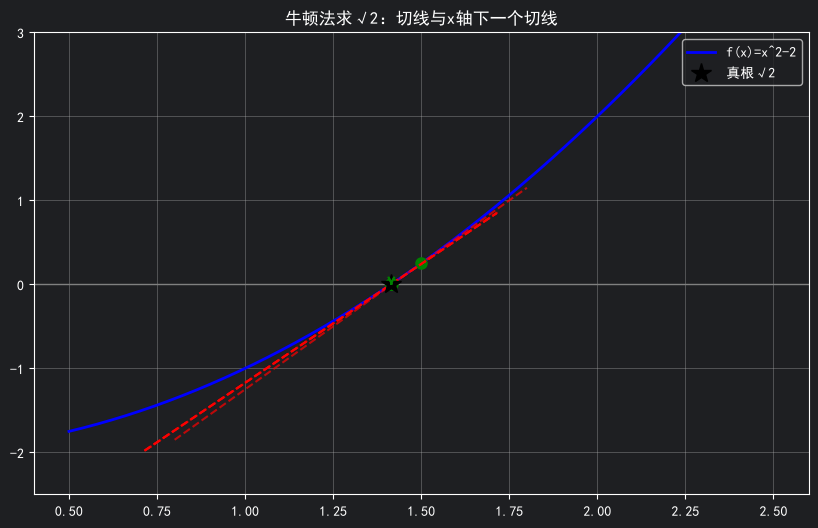

In [8]:
def f(x):return x**2-2
def fp(x): return 2*x
x = np.linspace(0.5, 2.5, 200)
plt.figure(figsize=(10, 6))
plt.plot(x, f(x), 'b-', linewidth=2, label='f(x)=x^2-2')
plt.axhline(0, color='gray', linewidth=1)

x_cur = 1.5
for i in range(5):
    fx,fpx = f(x_cur),fp(x_cur)
    x_tan = np.linspace(x_cur-0.7,x_cur+0.3,50)
    plt.plot(x_tan, fx + fpx*(x_tan - x_cur), 'r--', alpha=0.7)
    plt.plot(x_cur, fx, 'go', markersize=8)
    x_next = x_cur - fx / fpx
    plt.annotate('', xy=(x_next, 0), xytext=(x_next, f(x_next)),
                 arrowprops=dict(arrowstyle='->', color='green'))
    x_cur = x_next

plt.plot(2**0.5,0,'k*',markersize=15,label='真根√2')
plt.ylim(-2.5,3)
plt.legend()
plt.grid(True)
plt.title('牛顿法求√2：切线与x轴下一个切线')
plt.show()

In [9]:
#牛顿法与梯度下降法的对比

def f_opt(x): return (x-3)**2 + 1
def fp(x): return 2*(x-3)        # 一阶导数
def fpp_opt(x): return 2         # 二阶导数

x0 = 0.0

# 梯度下降法
x_gd = x0
eta = 0.1
for i in range(20):
    x_gd = x_gd - eta * fp(x_gd)
print(f'梯度下降20步：x = {x_gd:.6f}（真值 3.0）')

# 牛顿法
x_nt = x0
for i in range(5):
    x_nt = x_nt - fp(x_nt) / fpp_opt(x_nt)
print(f'牛顿法5步：x = {x_nt:.6f}（真值 3.0）')


梯度下降20步：x = 2.965412（真值 3.0）
牛顿法5步：x = 3.000000（真值 3.0）
